**SVM**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
path='/content/drive/My Drive/ML Lab/Exp06/studentresult.csv'
df=pd.read_csv(path)
print(df)

    Study_Hours  Attendance  Assignment_Score  Result
0           1.0          45                35       0
1           1.5          50                40       0
2           2.0          52                42       0
3           2.0          56                45       0
4           2.5          55                44       0
5           2.8          58                48       0
6           3.0          60                50       0
7           3.0          63                52       0
8           3.5          61                49       0
9           3.7          65                55       0
10          4.0          66                58       0
11          4.0          68                60       0
12          4.2          70                62       1
13          4.5          69                61       1
14          4.7          72                65       1
15          5.0          74                68       1
16          5.0          76                70       1
17          5.2          73 

In [ ]:
#Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
X=df[['Assignment_Score','Attendance']]
Y=df['Result']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = SVC(kernel='linear')
model.fit(X_scaled,Y)

SVC(kernel='linear')

In [ ]:
#Split Dataset
from sklearn.model_selection import train_test_split

X = df[['Assignment_Score', 'Attendance']]
y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


Kernel: linear
Accuracy: 0.8571428571428571

Kernel: poly
Accuracy: 0.8571428571428571

Kernel: rbf
Accuracy: 0.8571428571428571


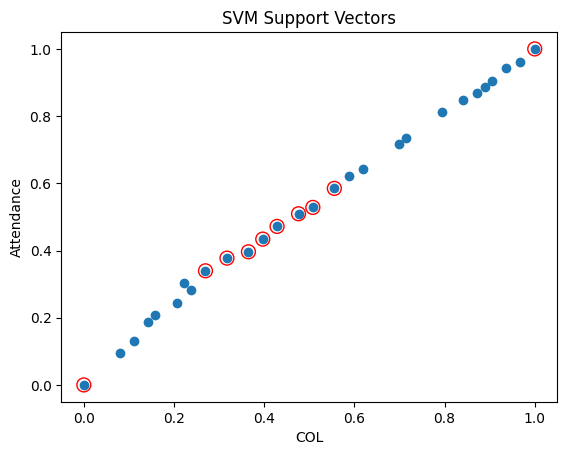

Best Parameters:
{'C': 1, 'gamma': 1}
Final Accuracy: 0.8571428571428571


In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train SVM model
kernels = ['linear', 'poly', 'rbf']
for kernel in kernels:
    model = SVC(kernel=kernel)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print("\nKernel:", kernel)
    print("Accuracy:", accuracy)

# Plot data points
plt.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1])

# Plot support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=100,
    facecolors='none',
    edgecolors='red'
)

plt.xlabel("COL")
plt.ylabel("Attendance")
plt.title("SVM Support Vectors")

plt.show()


# Values to test
parameters = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}
# Create GridSearchCV
grid = GridSearchCV(
    SVC(kernel='rbf'),
    parameters,
    cv=5
)

# Train
grid.fit(X_train, y_train)

# Best values
print("Best Parameters:")
print(grid.best_params_)

# Test the best model
y_pred = grid.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Final Accuracy:", accuracy)